# Comparing UCSF to Yale

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for all plots in notebook
file = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_16_UCSF_1source/UCSF_test_1source_Yb_1e7_85_2.5.csv"
z_slice = 25
norm_point = (0.0, 0.3)
bins = 85
dose_grid_half = 2.5
lattice = dose_grid_half*2/bins
source_transZ = -0.5
source_plane = cm_to_voxel(np.array(source_transZ), bins, dose_grid_half*2/bins)
applicator_rad = 0.3
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

In [4]:
norm_energy, __ = extract_norm_energy(file, source_plane, 2, norm_point, bins, lattice)

In [5]:
X, Y, energy, __ = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad[3], 
                                               scale=False, norm_energy=norm_energy, zero_source=True, std_dev=False)

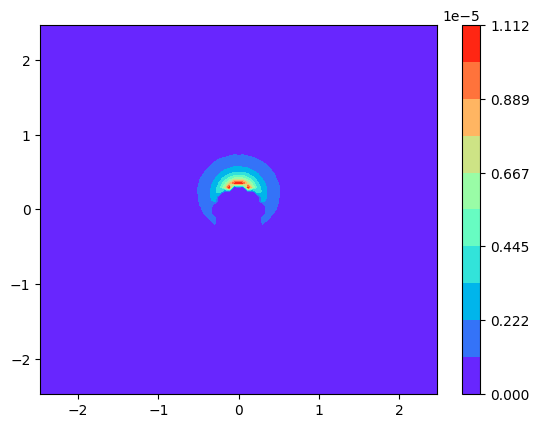

In [6]:
fig0, ax0 = plt.subplots()
contour0 = ax0.contourf(X, Y, energy, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar0 = fig0.colorbar(contour0)

In [7]:
# Comparison to MOSH - 5 rods inserted, 12 o'clock position open
file2 = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"

In [8]:
norm_energy2, __ = extract_norm_energy(file2, source_plane, 2, norm_point, bins, lattice)

In [9]:
X2, Y2, energy2, __ = contour_energy(file2, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=False, norm_energy=norm_energy, zero_source=True, std_dev=False)

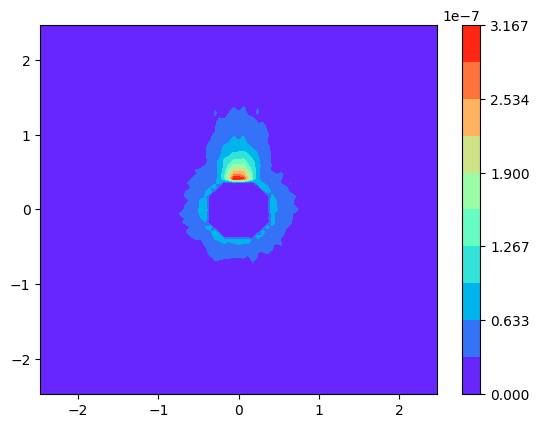

In [10]:
fig1, ax1 = plt.subplots()
contour1 = ax1.contourf(X2, Y2, energy2, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar1 = fig1.colorbar(contour1)

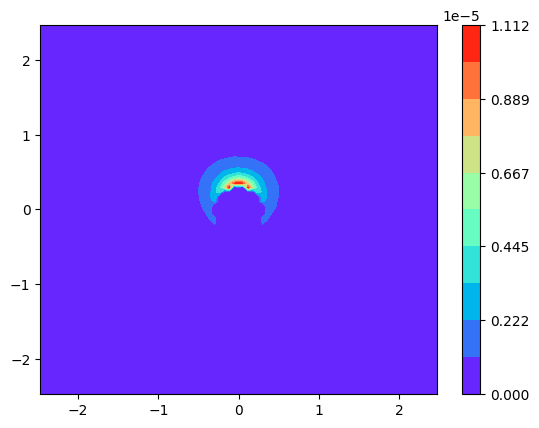

In [11]:
comparison = energy - energy2

fig2, ax2 = plt.subplots()
contour2 = ax2.contourf(X, Y, comparison, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar2 = fig2.colorbar(contour2)

In [12]:
# Note how MOSH delivers a much smaller dose to the region just outside the applicator, so the plot is almost unchanged
# Compare dose drop-off of UCSF and MOSH on same plot

lin_energy_ucsf, __ = energy_along_theta(file, pi/2, (bins, bins), dose_grid_half, source_plane, scale=True, norm_energy=norm_energy)
x, y1, __, __, __ = plotter_1D(lin_energy_ucsf, plot_rng=(0.237, 1.0)) 

lin_energy_mosh, __ = energy_along_theta(file2, pi/2, (bins, bins), dose_grid_half, source_plane, scale=True, norm_energy=norm_energy)
x, y2, __, __, __ = plotter_1D(lin_energy_mosh, plot_rng=(0.237, 1.0)) 

difference = y1 - y2

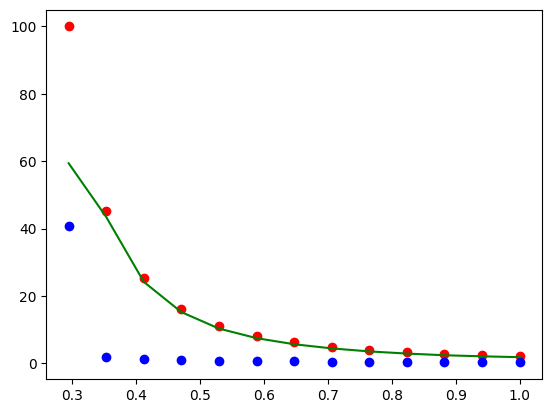

In [13]:
fig3, ax3 = plt.subplots()
ax3.scatter(x, y1, color="red")
ax3.scatter(x, y2, color="blue")
ax3.plot(x, difference, color="green")

## New UCSF applicator - initial visualization

In [14]:
fileNew = "/Users/seanmullane/Desktop/Research_2023/Sept_outputs/removed23_1e7_75bins_2.55cmHL.csv"
binsNew = 75
dose_grid_new = 2.55
latticeNew = dose_grid_new*2/binsNew
source_plane_new = cm_to_voxel(np.array(source_transZ), binsNew, dose_grid_new*2/binsNew)

norm_energy_new, __ = extract_norm_energy(fileNew, source_plane_new, 2, norm_point, binsNew, latticeNew)

In [15]:
Xn, Yn, energyn, __ = contour_energy(fileNew, (binsNew, binsNew), dose_grid_new, source_plane_new, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy_new, zero_source=True, std_dev=False)

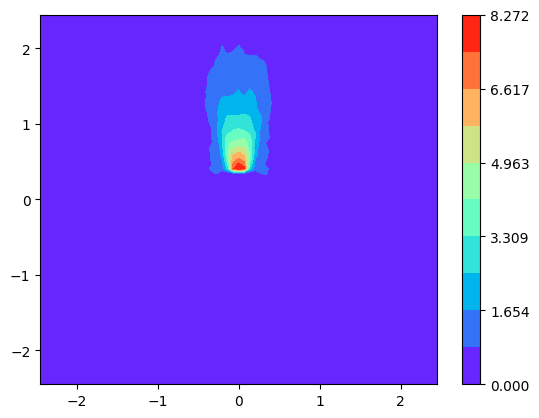

In [16]:
fign, axn = plt.subplots()
contourn = axn.contourf(Xn, Yn, energyn, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbarn = fign.colorbar(contourn)

In [17]:
fileNew2 = "/Users/seanmullane/Desktop/Research_2023/Sept_outputs/removed23461112_1e7_75bins_2.55cmHL.csv"

norm_energy_new2, __ = extract_norm_energy(fileNew2, source_plane_new, 2, norm_point, binsNew, latticeNew)

In [18]:
Xn2, Yn2, energyn2, __ = contour_energy(fileNew2, (binsNew, binsNew), dose_grid_new, source_plane_new, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy_new2, zero_source=True, std_dev=False)

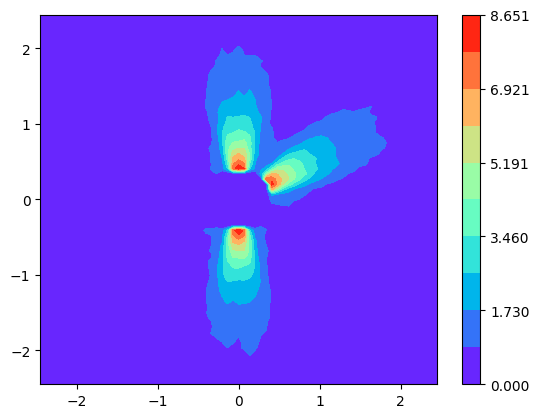

In [19]:
fign2, axn2 = plt.subplots()
contourn2 = axn2.contourf(Xn2, Yn2, energyn2, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbarn2 = fign2.colorbar(contourn2)

In [20]:
# Comparis 1, 2, 4 UCSF distribution to MOSH
mosh1 = "/Users/seanmullane/Desktop/Research_2023/Sept_outputs/3rods_positions146_1e7_75bins_2.55cmHL.csv"

# Use same normalization energy as above for fair comparison of dose
#norm_energy_mosh1, __ = extract_norm_energy(mosh1, source_plane_new, 2, norm_point, binsNew, latticeNew)

In [21]:
X3, Y3, energy3, __ = contour_energy(mosh1, (binsNew, binsNew), dose_grid_new, source_plane_new, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy_new2, zero_source=True, std_dev=False)

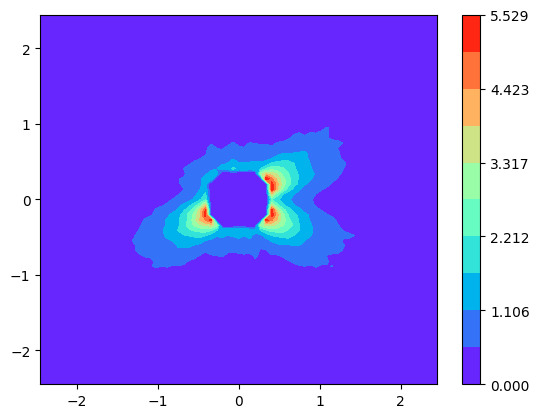

In [22]:
fig3, ax3 = plt.subplots()
contour3 = ax3.contourf(X3, Y3, energy3, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar3 = fig3.colorbar(contour3)